## import thư viện

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
df = pd.read_csv(r'data/train.csv')


## PHẦN 1:Tổng quan dữ liệu

- 2930 giao dịch bán nhà ở Ames, Iowa (2006-2010)
- 80 biến: 20 liên tục, 14 rời rạc, 23 định danh, 23 thứ tự
- Biến mục tiêu: `SalePrice`
- `PID` chỉ là mã thửa đất, không có ý nghĩa dự báo nên bỏ khi phân tích


Dữ liệu là giao dịch bán nhà ở Ames, Iowa (2006-2010), theo paper của De Cock (2011) có 2930 giao dịch và 80 biến. File đang dùng là `train.csv` (bản Kaggle House Prices, chia từ cùng bộ dữ liệu này), nên chỉ có:

- 1460 dòng, 81 cột (gồm `Id` và biến mục tiêu `SalePrice`)
- 38 cột số, 43 cột chữ
- `Id` chỉ là số thứ tự, không dùng để dự báo

In [6]:
df.shape

(1460, 81)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

### 1.1.Phân loại biến

- **Liên tục:** chủ yếu là các loại diện tích (lô đất, tầng hầm, diện tích sinh hoạt, hiên...)
- **Rời rạc:** số phòng ngủ, phòng tắm, bếp, sức chứa gara, năm xây/sửa
- **Định danh:** loại nhà, vật liệu, khu vực... trong đó `Neighborhood` có 28 mức, nhiều nhất
- **Thứ tự:** các thang chất lượng (chất lượng tổng thể, bếp, tầng hầm...)

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [9]:
df.select_dtypes(exclude='number').describe().T

,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,91,2,Grvl,50
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


### 1.2.Nhận xét ban đầu

- Dữ liệu 1460 x 81, nhiều cột thiếu (19 cột), nhiều cột bị thiếu đến 99% dữ liệu phải xem xét lại Dataset liệu có phải missing thật hay là thuộc tính của căn nhà là không có (không sở hữu) những đặc trưng này


In [10]:
skew = df.select_dtypes('number').skew().sort_values(ascending=False)
print("SalePrice skew:", df['SalePrice'].skew())
skew.head(10)

SalePrice skew: 1.8828757597682129


MiscVal          24.476794
PoolArea         14.828374
LotArea          12.207688
3SsnPorch        10.304342
LowQualFinSF      9.011341
KitchenAbvGr      4.488397
BsmtFinSF2        4.255261
ScreenPorch       4.122214
BsmtHalfBath      4.103403
EnclosedPorch     3.089872
dtype: float64

- `SalePrice` lệch phải (skew = 1), trung bình lớn hơn trung vị
- Các cột lệch mạnh nhất: MiscVal  (nhiều cột diện tích có phần lớn giá trị bằng 0, như `PoolArea`, `MiscVal`, `3SsnPorch`)

### 1.3.Ghi chú từ paper

- Tác giả khuyên loại nhà có `GrLivArea` > 4000 sq ft (5 điểm bất thường)
- Biến thứ tự và biến rời rạc có thể cho hệ số không đơn điệu khi mã hóa thành biến giả
- Hai ý này để dành cho phần outliers và phân tích đa biến

## PHẦN 2:PHÂN TÍCH ĐƠN BIẾN

Mục tiêu của phân tích đơn biến là khảo sát từng biến độc lập riêng lẻ để:
- hiểu phân bố của dữ liệu;
- nhận diện biến lệch phải/lệch trái;
- phát hiện giá trị 0, giá trị bất thường và ngoại lệ sơ bộ;
- với biến phân loại, xem tần suất xuất hiện của từng nhóm;
- xác định những biến cần chú ý trước khi thực hiện phân tích đa biến.

Phân tích được chia thành:
1. Biến số (`numeric`)
2. Biến phân loại (`categorical`)
3. Biến mục tiêu `SalePrice`

In [11]:
# Tách biến số và biến phân loại
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

# Không xem Id/PID là biến phân tích
numeric_analysis_cols = [c for c in numeric_cols if c not in ['Id', 'PID']]

print("Số biến số dùng để phân tích:", len(numeric_analysis_cols))
print("Số biến phân loại:", len(categorical_cols))

Số biến số dùng để phân tích: 37
Số biến phân loại: 43


### 2.1. Phân tích đơn biến đối với biến số

Trước tiên xem các đại lượng cơ bản: min, max, trung bình, trung vị, độ lệch chuẩn và độ lệch phân phối (`skewness`).

In [12]:
numeric_summary = df[numeric_analysis_cols].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).T

numeric_summary['skewness'] = df[numeric_analysis_cols].skew()
numeric_summary = numeric_summary.sort_values('skewness', ascending=False)

numeric_summary.head(20)

,count,mean,median,std,min,max,skewness
MiscVal,1460.0,43.489041,0.0,496.123024,0.0,15500.0,24.476794
PoolArea,1460.0,2.758904,0.0,40.177307,0.0,738.0,14.828374
LotArea,1460.0,10516.828082,9478.5,9981.264932,1300.0,215245.0,12.207688
3SsnPorch,1460.0,3.409589,0.0,29.317331,0.0,508.0,10.304342
LowQualFinSF,1460.0,5.844521,0.0,48.623081,0.0,572.0,9.011341
KitchenAbvGr,1460.0,1.046575,1.0,0.220338,0.0,3.0,4.488397
BsmtFinSF2,1460.0,46.549315,0.0,161.319273,0.0,1474.0,4.255261
ScreenPorch,1460.0,15.060959,0.0,55.757415,0.0,480.0,4.122214
BsmtHalfBath,1460.0,0.057534,0.0,0.238753,0.0,2.0,4.103403
EnclosedPorch,1460.0,21.954110,0.0,61.119149,0.0,552.0,3.089872


### Nhận xét

- `mean` và `median` giúp so sánh mức độ đối xứng của phân phối.
- Nếu `mean > median` đáng kể, biến thường có xu hướng lệch phải.
- `skewness > 0` cho thấy phân phối lệch phải; `skewness < 0` cho thấy lệch trái.
- Những biến có độ lệch lớn cần được chú ý vì có thể chứa nhiều giá trị rất lớn hoặc tập trung nhiều ở một vùng giá trị.

### 2.2. Phân phối của `SalePrice`

`SalePrice` là biến mục tiêu nên được khảo sát riêng trước khi phân tích mối quan hệ với các biến khác.

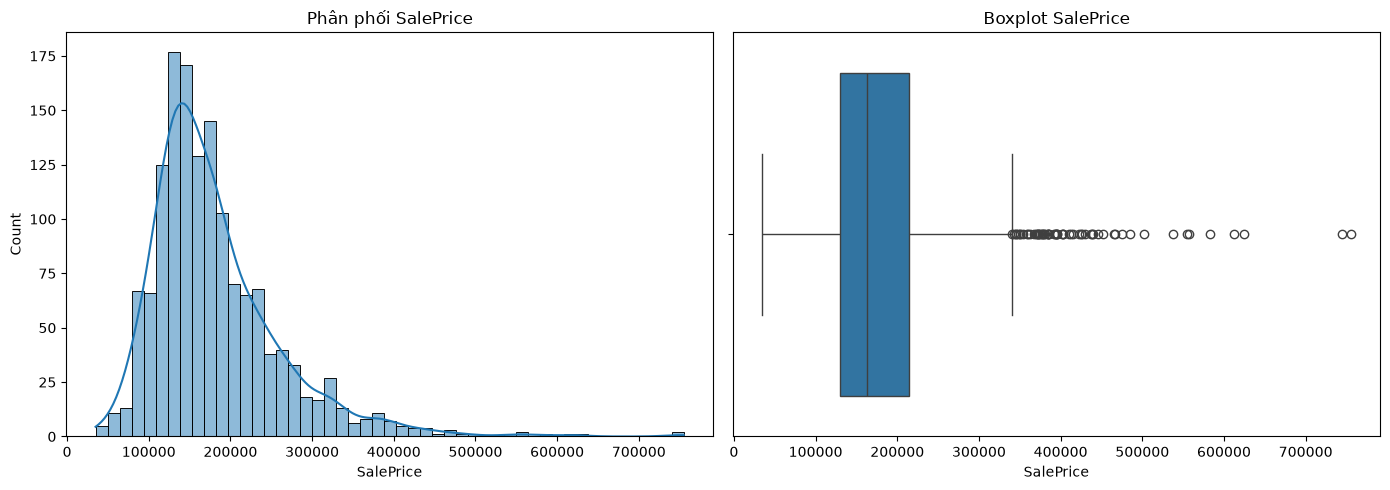

Mean: 180921.19589041095
Median: 163000.0
Skewness: 1.8828757597682129


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title('Phân phối SalePrice')
axes[0].set_xlabel('SalePrice')

sns.boxplot(x=df['SalePrice'], ax=axes[1])
axes[1].set_title('Boxplot SalePrice')
axes[1].set_xlabel('SalePrice')

plt.tight_layout()
plt.show()

print("Mean:", df['SalePrice'].mean())
print("Median:", df['SalePrice'].median())
print("Skewness:", df['SalePrice'].skew())

### Nhận xét về `SalePrice`

- Quan sát histogram để đánh giá hình dạng phân phối.
- So sánh mean và median để nhận biết độ lệch.
- Boxplot giúp quan sát các giá trị nằm xa phần lớn dữ liệu.
- Theo phần tổng quan trước đó, `SalePrice` có xu hướng **lệch phải**, do đó một số căn nhà có giá bán rất cao kéo dài đuôi phân phối về phía phải.

### 2.3. Phân tích các biến số quan trọng

Một số biến số có ý nghĩa trực tiếp đối với quy mô và đặc điểm căn nhà, ví dụ:
- `GrLivArea`: diện tích sinh hoạt trên mặt đất;
- `TotalBsmtSF`: tổng diện tích tầng hầm;
- `1stFlrSF`: diện tích tầng 1;
- `GarageArea`: diện tích gara;
- `YearBuilt`: năm xây dựng;
- `OverallQual`: chất lượng tổng thể.

Dùng histogram và boxplot để khảo sát phân phối của các biến này.

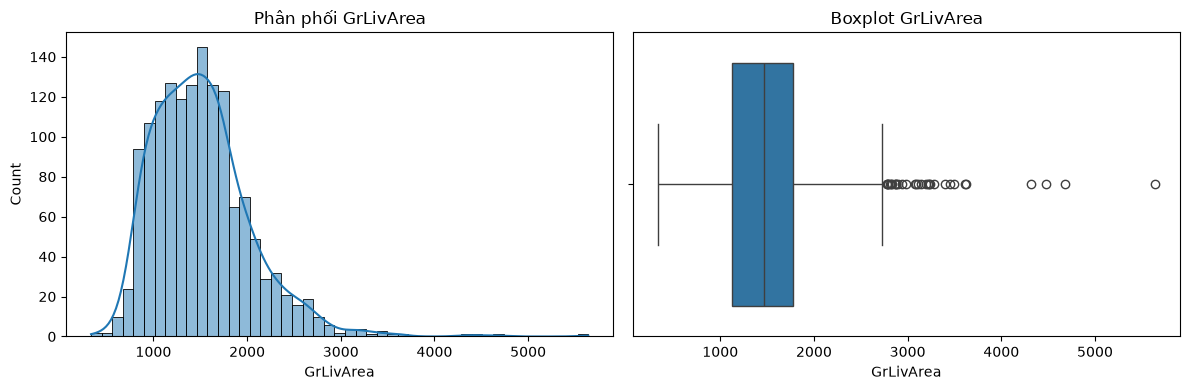

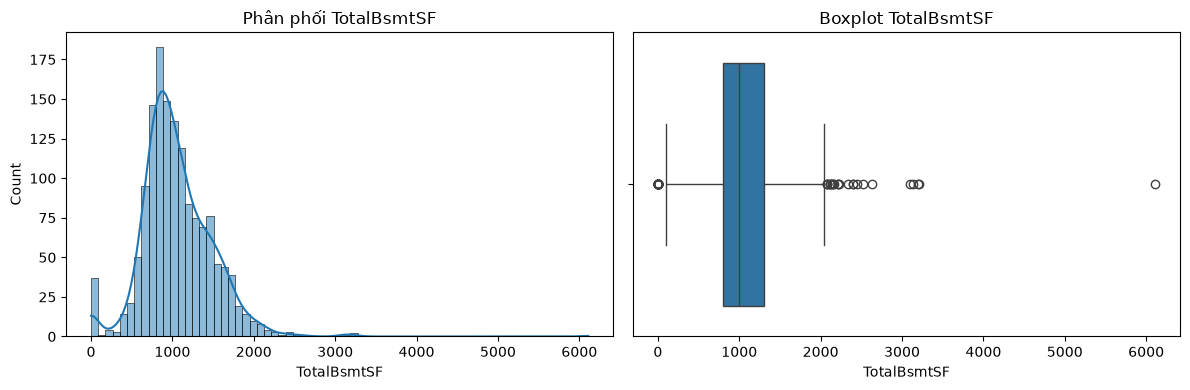

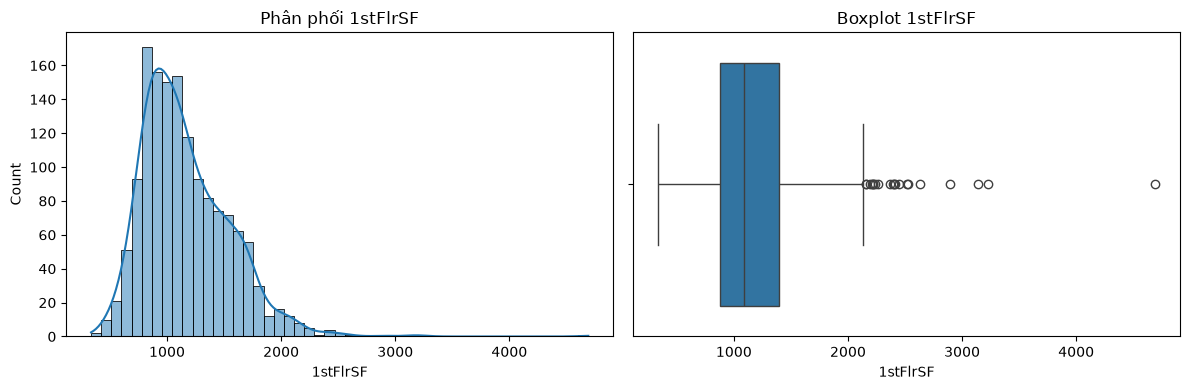

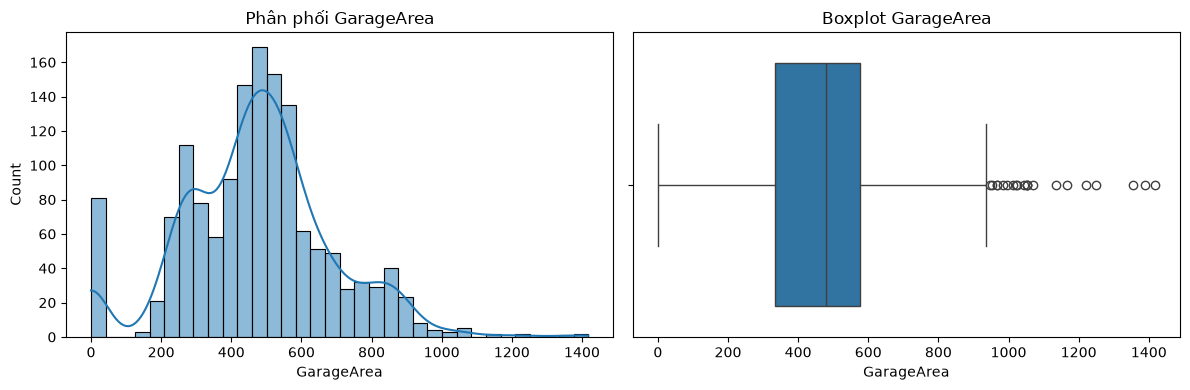

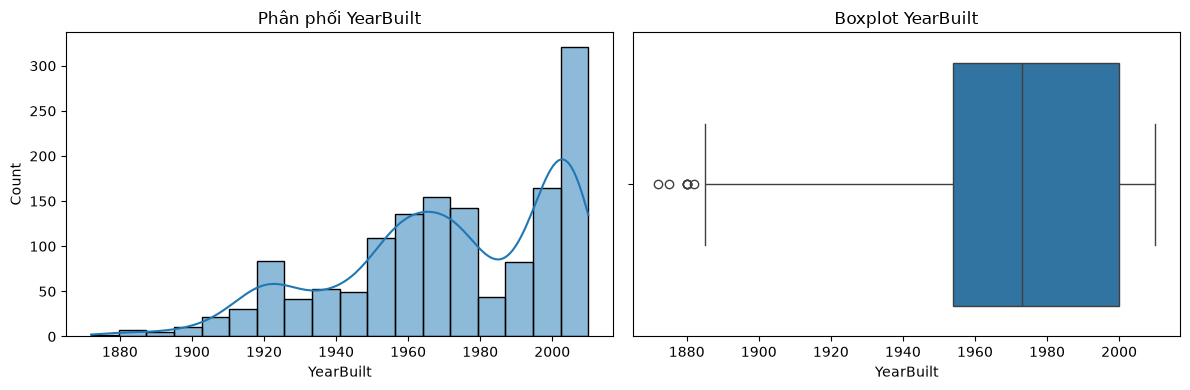

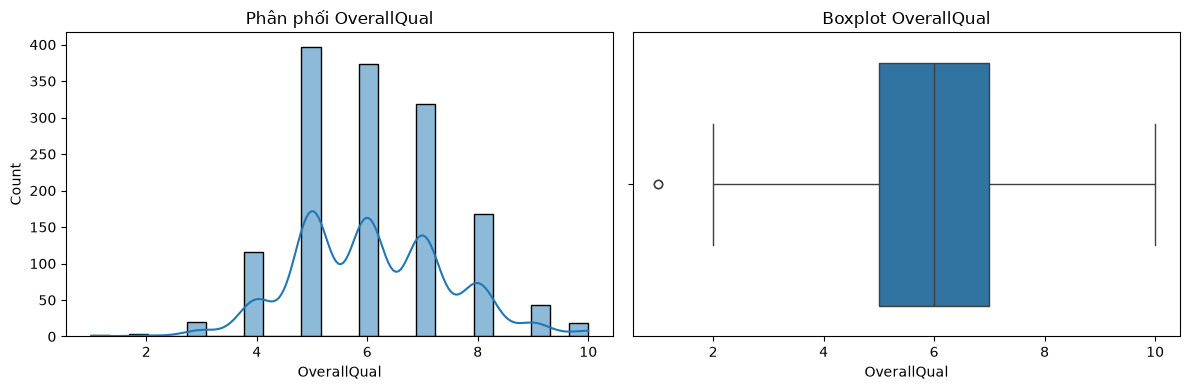

In [14]:
important_numeric = [
    c for c in [
        'GrLivArea', 'TotalBsmtSF', '1stFlrSF',
        'GarageArea', 'YearBuilt', 'OverallQual'
    ] if c in df.columns
]

for col in important_numeric:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(df[col].dropna(), kde=True, ax=axes[0])
    axes[0].set_title(f'Phân phối {col}')

    sns.boxplot(x=df[col], ax=axes[1])
    axes[1].set_title(f'Boxplot {col}')

    plt.tight_layout()
    plt.show()

### 2.4. Phân tích đơn biến đối với biến phân loại

Với biến phân loại, thay vì tính trung bình, ta quan sát số lượng và tỷ lệ của từng nhóm. Điều này giúp phát hiện:
- nhóm chiếm đa số;
- nhóm rất hiếm;
- biến có quá nhiều mức;
- nhóm có tần suất bằng 0 hoặc gần 0.

In [15]:
# Bảng tần suất của các biến phân loại
for col in categorical_cols:
    print(f'\n===== {col} =====')
    freq = df[col].value_counts(dropna=False)
    print(freq.head(15))
    print("Số mức:", df[col].nunique(dropna=False))


===== MSZoning =====
MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64
Số mức: 5

===== Street =====
Street
Pave    1454
Grvl       6
Name: count, dtype: int64
Số mức: 2

===== Alley =====
Alley
NaN     1369
Grvl      50
Pave      41
Name: count, dtype: int64
Số mức: 3

===== LotShape =====
LotShape
Reg    925
IR1    484
IR2     41
IR3     10
Name: count, dtype: int64
Số mức: 4

===== LandContour =====
LandContour
Lvl    1311
Bnk      63
HLS      50
Low      36
Name: count, dtype: int64
Số mức: 4

===== Utilities =====
Utilities
AllPub    1459
NoSeWa       1
Name: count, dtype: int64
Số mức: 2

===== LotConfig =====
LotConfig
Inside     1052
Corner      263
CulDSac      94
FR2          47
FR3           4
Name: count, dtype: int64
Số mức: 5

===== LandSlope =====
LandSlope
Gtl    1382
Mod      65
Sev      13
Name: count, dtype: int64
Số mức: 3

===== Neighborhood =====
Neighborhood
NAmes      225
CollgCr    150
OldTown   

### 2.5. Trực quan hóa một số biến phân loại quan trọng

Có thể dùng biểu đồ cột cho các biến có số lượng mức vừa phải. `Neighborhood`, `HouseStyle`, `BldgType`, `KitchenQual` và `ExterQual` là những biến có thể khảo sát trước.

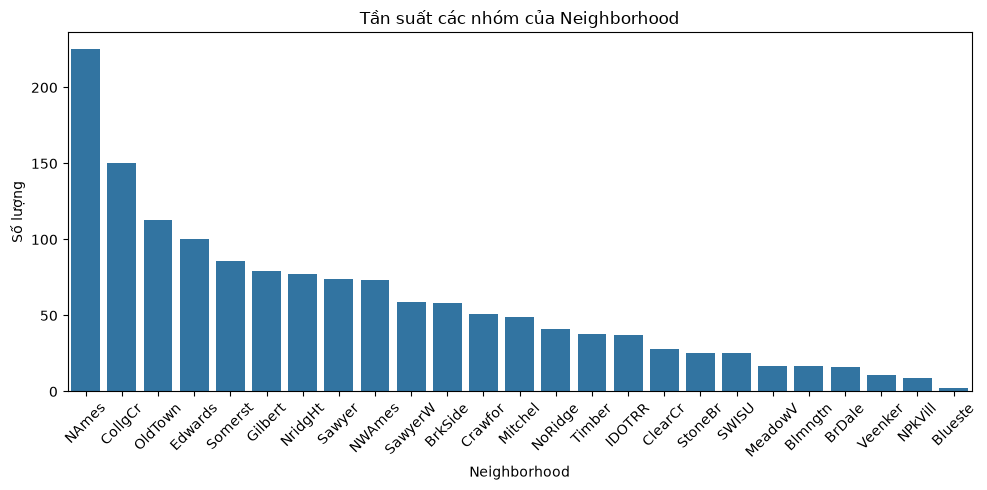

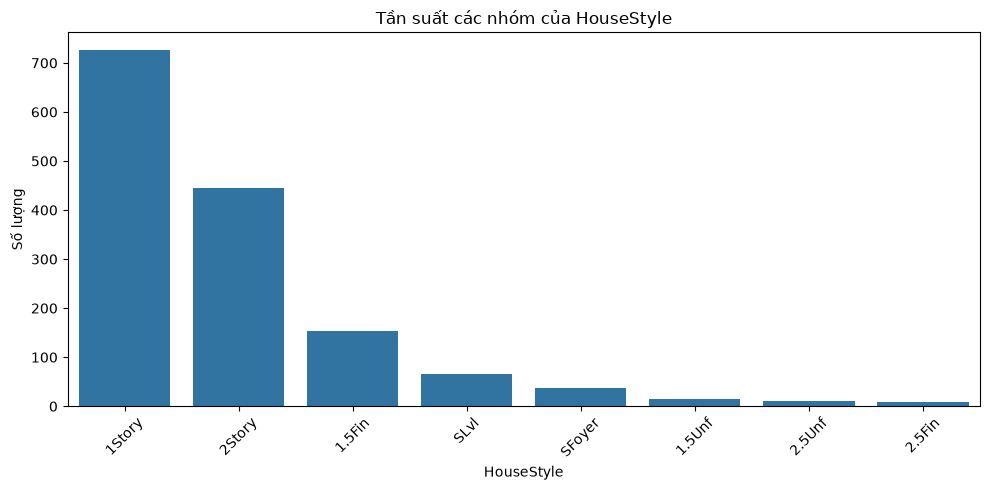

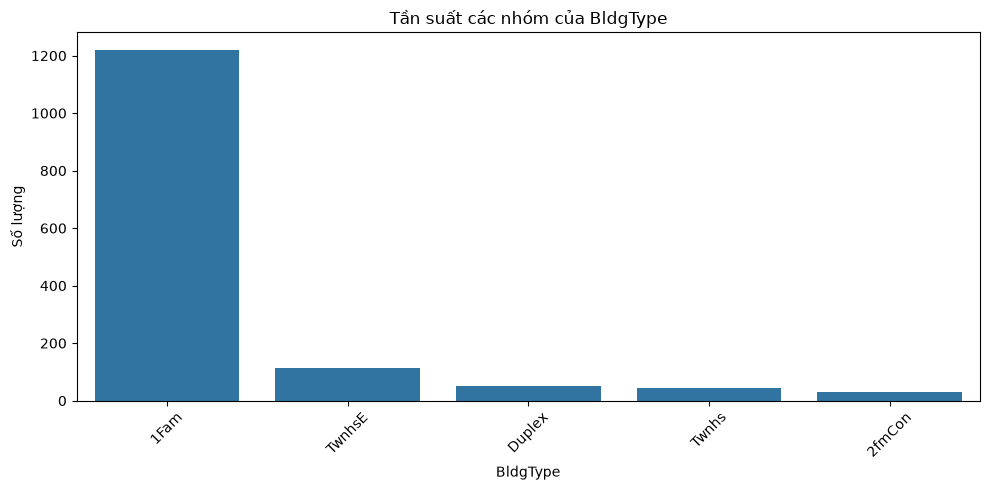

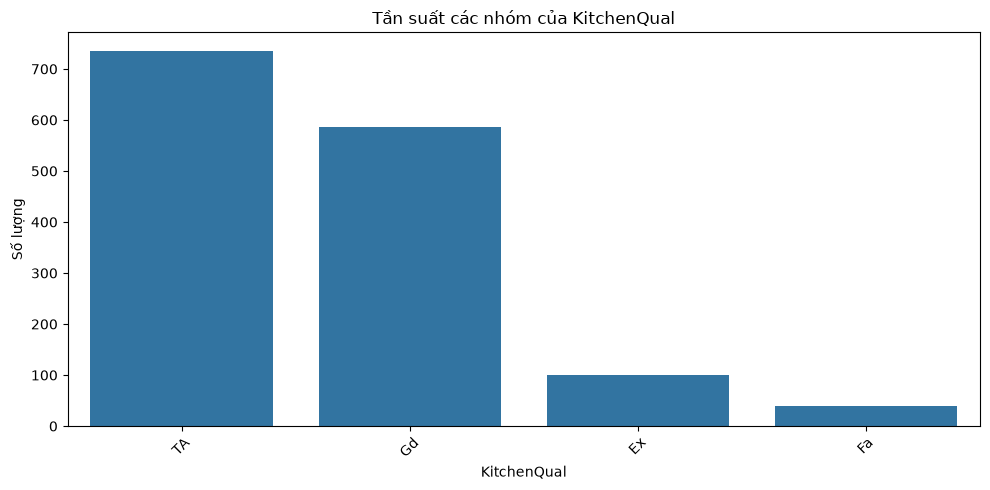

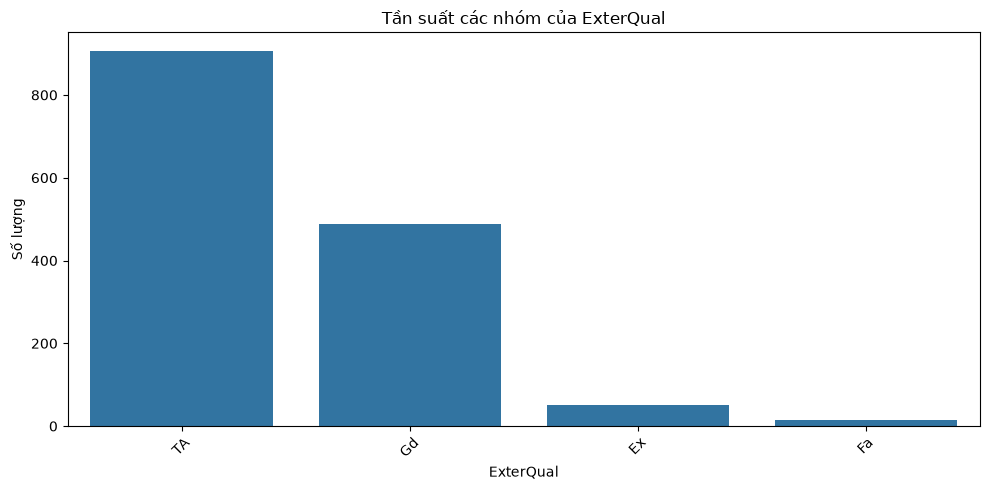

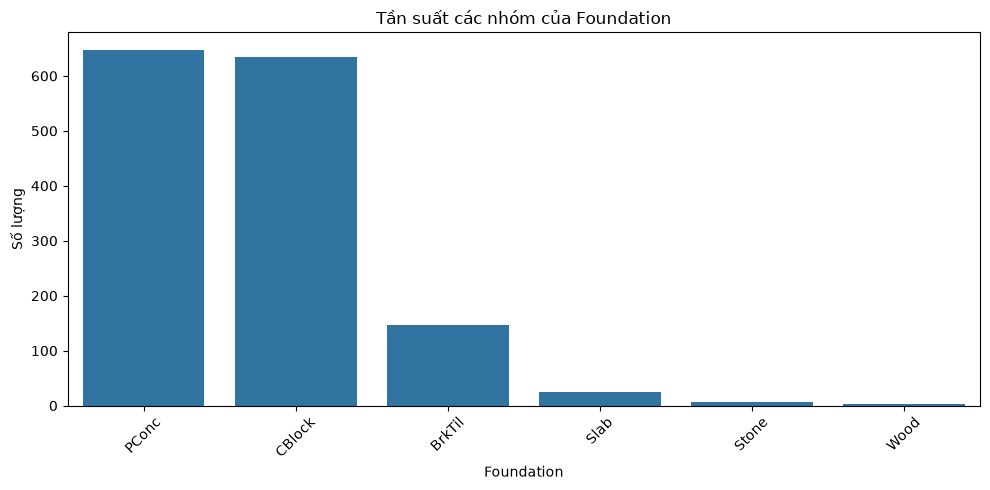

In [16]:
important_categorical = [
    c for c in [
        'Neighborhood', 'HouseStyle', 'BldgType',
        'KitchenQual', 'ExterQual', 'Foundation'
    ] if c in df.columns
]

for col in important_categorical:
    order = df[col].value_counts().index

    plt.figure(figsize=(10, 5))
    sns.countplot(data=df, x=col, order=order)
    plt.title(f'Tần suất các nhóm của {col}')
    plt.xlabel(col)
    plt.ylabel('Số lượng')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### 2.6. Tổng hợp kết quả phân tích đơn biến

Từ phân tích đơn biến, có thể ghi nhận:

- `SalePrice` có phân phối lệch phải, cần chú ý khi xây dựng mô hình.
- Một số biến diện tích có nhiều giá trị bằng 0; cần phân biệt đây là **không có đặc trưng đó** hay dữ liệu bị thiếu.
- Một số biến số có độ lệch lớn, cần kiểm tra thêm bằng boxplot và phân tích đa biến.
- Các biến phân loại có số lượng mức khác nhau; một số biến có thể có nhóm rất hiếm.
- `GrLivArea` cần được chú ý khi kiểm tra ngoại lệ. Phần kiểm tra ngoại lệ chi tiết sẽ được thực hiện ở bước tiếp theo, kết hợp với thông tin từ paper của De Cock.
- Phân tích đơn biến mới chỉ mô tả từng biến riêng lẻ; chưa thể kết luận biến nào thực sự ảnh hưởng mạnh đến `SalePrice`. Điều đó cần được kiểm tra ở **phân tích đa biến**.